# EnsembleX LK: Explainable Ensemble Learning for Sri Lankan Used-Vehicle Price Prediction

**Project type:** Supervised regression  
**Dataset:** Sri Lankan used-vehicle listings; 9,788 records, 17 columns  
**Source:** [Kaggle](https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset) (`prasadnirmal/srilankan-second-vehiclecar-price-dataset`)  
**Objective:** Estimate asking prices using tree-based ensemble models.

The target, `Price`, is measured in LKR lakhs. The analysis compares individual and ensemble methods using MAE, RMSE and R², then interprets the selected model with permutation feature importance. Listings represent asking prices, not confirmed transaction values.

## 1. Notebook Organisation

This notebook covers data loading, validation, EDA, preprocessing, model training, evaluation, explainability and artifact export. Run the cells sequentially using the documented Kaggle dataset and required Python libraries.

## 2. Environment and Dependencies

The dependencies support data processing, modelling, visualisation and model serialisation. Installation may take a few minutes in a fresh environment.

In [ ]:
%pip -q install -U xgboost catboost shap plotly streamlit joblib

## 3. Library imports and reproducibility

The imports cover data manipulation, numerical computation, visualisation, preprocessing, regression estimators, evaluation metrics and model persistence. A fixed random seed is used where supported so that the train-test split and stochastic modelling steps are reproducible within the same software environment.

In [ ]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import joblib

from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, StackingRegressor,
    VotingRegressor
)
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("scikit-learn:", sklearn_version)
print("Environment ready.")

scikit-learn: 1.6.1
Environment ready.


## 4. Dataset source and loading

The dataset is obtained from the Kaggle collection **Sri Lankan Second Vehicle/Car Price Dataset** (`prasadnirmal/srilankan-second-vehiclecar-price-dataset`). The original file contains 9,788 listings and 17 columns.

The next cell downloads the dataset and locates its CSV file. The source dataset includes an exported index field (`Unnamed: 0`), vehicle characteristics, listing information and the target `Price`. The index field is retained for the initial data audit but is excluded from predictive modelling.

In [25]:

!pip install -q kagglehub

import kagglehub
import pandas as pd
import os
import glob

# Download the original Kaggle dataset
path = kagglehub.dataset_download(
    "prasadnirmal/srilankan-second-vehiclecar-price-dataset"
)

print("Dataset downloaded to:", path)

# Find the CSV file
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("Available CSV files:", csv_files)

# Load the dataset
raw_df = pd.read_csv(csv_files[0])

print("Dataset shape:", raw_df.shape)
display(raw_df.head())


Using Colab cache for faster access to the 'srilankan-second-vehiclecar-price-dataset' dataset.
Dataset downloaded to: /kaggle/input/srilankan-second-vehiclecar-price-dataset
Available CSV files: ['/kaggle/input/srilankan-second-vehiclecar-price-dataset/car_price_dataset.csv']
Dataset shape: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 5. Dataset audit and data quality

The initial audit examines the raw column names, data types, missing values, duplicate records and descriptive statistics. In the dataset used for this experiment, the audit reports **no missing values and no duplicate rows** across the 9,788 records.

These checks establish the quality of the supplied snapshot; they do not guarantee that a subsequently downloaded or substituted file will have the same contents. The following validation cell checks that the expected feature and target columns are present.

In [26]:
print("COLUMN NAMES")
print(raw_df.columns.tolist())

print("\nDATA TYPES")
display(raw_df.dtypes.astype(str).rename("dtype").to_frame())

print("\nMISSING VALUES")
missing_report = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_report)

print("\nDUPLICATE ROWS:", raw_df.duplicated().sum())
print("\nNUMERICAL SUMMARY")
display(raw_df.describe(include="all").T)

COLUMN NAMES
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']

DATA TYPES


,dtype
Unnamed: 0,int64
Brand,object
Model,object
YOM,int64
Engine (cc),float64
Gear,object
Fuel Type,object
Millage(KM),float64
Town,object
Date,object



MISSING VALUES


,missing_count,missing_percent
Unnamed: 0,0,0.0
Brand,0,0.0
Model,0,0.0
YOM,0,0.0
Engine (cc),0,0.0
Gear,0,0.0
Fuel Type,0,0.0
Millage(KM),0,0.0
Town,0,0.0
Date,0,0.0



DUPLICATE ROWS: 0

NUMERICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,9788.0,NaN,NaN,NaN,4893.758991,2826.028988,0.0,2446.75,4893.5,7341.25,9788.0
Brand,9788,50,TOYOTA,3089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,9788,1555,ALTO,392,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YOM,9788.0,NaN,NaN,NaN,2006.759093,9.831574,1956.0,2001.0,2009.0,2015.0,2024.0
Engine (cc),9788.0,NaN,NaN,NaN,1260.442358,403.769059,573.0,1000.0,1300.0,1500.0,4800.0
Gear,9788,2,Automatic,6305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fuel Type,9788,4,Petrol,7866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Millage(KM),9788.0,NaN,NaN,NaN,200649.979567,108147.31486,11000.0,110000.0,176000.0,264000.0,759000.0
Town,9788,107,Colombo,1038,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,9788,65,2025-02-05,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5.1 Expected dataset schema

The 17 source columns are: `Unnamed: 0`, `Brand`, `Model`, `YOM`, `Engine (cc)`, `Gear`, `Fuel Type`, `Millage(KM)`, `Town`, `Date`, `Leasing`, `Condition`, `AIR CONDITION`, `POWER STEERING`, `POWER MIRROR`, `POWER WINDOW` and `Price`.

`Unnamed: 0` is an exported row-index field rather than a vehicle characteristic, so it is not used as a predictor. The target is `Price`, recorded in the original dataset units (LKR lakhs for this project). The dataset represents advertised asking prices rather than verified completed transactions.

In [ ]:
TARGET = "Price"
required_columns = [
    "Brand", "Model", "YOM", "Engine (cc)", "Gear", "Fuel Type",
    "Millage(KM)", "Town", "Date", "Leasing", "Condition",
    "AIR CONDITION", "POWER STEERING", "POWER MIRROR",
    "POWER WINDOW", TARGET
]
missing_columns = [c for c in required_columns if c not in raw_df.columns]
if missing_columns:
    raise ValueError(f"Expected columns missing from uploaded CSV: {missing_columns}")

print("All expected feature and target columns are present.")

All expected feature and target columns are present.


## 6. Data cleaning and feature engineering

The raw dataset is copied before transformations are applied. The exported index field is removed, numeric columns are converted to numeric types, and `Date` is parsed as a datetime value.

The workflow derives three time-related features. `Listing_Year` is the calendar year in which the listing was posted; `Listing_Month` represents the month of listing; and `Vehicle_Age` is calculated as `Listing_Year − YOM`, measuring vehicle age at the time of listing. This avoids calculating vehicle age relative to the current year.

Rows without a usable target and rows with non-positive prices are excluded. Implausible negative mileage, non-positive engine capacity and negative vehicle age are converted to missing values so that the preprocessing pipeline can handle them. High-price observations are not automatically removed. The printed diagnostics report the number of affected records.

In [ ]:
df = raw_df.copy()

# Remove an exported row-index column if present; it is not a predictive feature.
index_like = [c for c in df.columns if c.lower().startswith("unnamed:")]
df = df.drop(columns=index_like, errors="ignore")

# Convert expected numeric columns safely.
for col in ["YOM", "Engine (cc)", "Millage(KM)", TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse listing date. Invalid dates become NaT and are handled below.
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove rows without a valid target; supervised learning requires a target.
before = len(df)
df = df.dropna(subset=[TARGET]).copy()
print(f"Rows removed for missing/unparseable target: {before - len(df)}")

# Exclude non-positive target values as invalid prices; report how many.
invalid_target = df[TARGET] <= 0
print("Non-positive target rows removed:", int(invalid_target.sum()))
df = df.loc[~invalid_target].copy()

# Derive vehicle age at the time the listing was posted, rather than using
# the current year. Missing/invalid dates fall back to the dataset's modal
# listing year, which is learned from the data (not hard-coded).
listing_year = df["Date"].dt.year
fallback_year = int(listing_year.dropna().mode().iloc[0]) if listing_year.notna().any() else 2025
df["Listing_Year"] = listing_year.fillna(fallback_year).astype(int)
df["Vehicle_Age"] = df["Listing_Year"] - df["YOM"]

# Date-derived seasonality. Raw Date is not passed to the model.
df["Listing_Month"] = df["Date"].dt.month
df["Listing_Month"] = df["Listing_Month"].fillna(
    df["Listing_Month"].mode().iloc[0] if df["Listing_Month"].notna().any() else 1
).astype(int)

# Flag implausible values for transparent inspection. We do not silently
# remove high-price outliers; tree models can accommodate skew and rare cases.
print("Negative vehicle ages:", int((df["Vehicle_Age"] < 0).sum()))
print("Negative mileage:", int((df["Millage(KM)"] < 0).sum()))
print("Non-positive engine capacities:", int((df["Engine (cc)"] <= 0).sum()))

# Keep rows with implausible numeric predictors for now; imputation and
# robust tree ensembles are used. Replace physically invalid negative mileage
# and non-positive engine capacity with missing values so imputers handle them.
df.loc[df["Millage(KM)"] < 0, "Millage(KM)"] = np.nan
df.loc[df["Engine (cc)"] <= 0, "Engine (cc)"] = np.nan
df.loc[df["Vehicle_Age"] < 0, "Vehicle_Age"] = np.nan

# Remove rows with no usable core identity? No; categorical imputers handle them.
print("Final modelling dataset:", df.shape)
display(df.head())

Rows removed for missing/unparseable target: 0
Non-positive target rows removed: 0
Negative vehicle ages: 0
Negative mileage: 0
Non-positive engine capacities: 0
Final modelling dataset: (9788, 19)


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price,Listing_Year,Vehicle_Age,Listing_Month
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0,2025,9.0,2
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0,2025,8.0,1
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5,2025,7.0,1
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0,2024,7.0,12
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5,2024,7.0,12


## 7. Exploratory data analysis

The exploratory analysis describes the distribution of asking prices and the composition of the listings by town and brand. The plots help identify skewness, spread, common categories and potential relationships between vehicle attributes and advertised price.

The target distribution is broad and right-skewed, with a small number of high-priced listings. Such observations are not automatically data errors. Visual patterns and group differences are descriptive and should not be interpreted as evidence that a particular attribute causes a price change.

In [ ]:
print("Target summary:")
display(df[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame())

fig = px.histogram(df, x=TARGET, nbins=60, marginal="box",
                   title="Distribution of advertised vehicle prices",
                   labels={TARGET: "Price (original dataset units)"})
fig.show()

fig = px.box(df, x="Gear", y=TARGET, points="outliers",
             title="Advertised price by transmission")
fig.show()

top_brands = df["Brand"].value_counts().head(15).index
brand_view = df[df["Brand"].isin(top_brands)]
fig = px.box(brand_view, x="Brand", y=TARGET, title="Price distribution for 15 most frequent brands")
fig.update_layout(xaxis_tickangle=-45)
fig.show()

fig = px.scatter(df.sample(min(2500, len(df)), random_state=RANDOM_STATE),
                 x="Millage(KM)", y=TARGET, color="Gear",
                 hover_data=["Brand", "Model", "YOM"],
                 title="Mileage versus advertised price (sample of up to 2,500 listings)")
fig.show()

print("Most frequent towns:")
display(df["Town"].value_counts().head(15).to_frame("listing_count"))
print("Most frequent brands:")
display(df["Brand"].value_counts().head(15).to_frame("listing_count"))

Target summary:


,Price
count,9788.000000
mean,53.464275
std,43.625049
min,2.650000
1%,6.243500
5%,10.500000
25%,26.250000
50%,43.000000
75%,69.750000
95%,125.000000


Most frequent towns:


,listing_count
Town,
Colombo,1038
Gampaha,657
Kurunegala,646
Kandy,637
Matara,319
Malabe,273
Galle,253
Kadawatha,235
Negombo,228


Most frequent brands:


,listing_count
Brand,
TOYOTA,3089
SUZUKI,2473
NISSAN,1248
HONDA,681
MITSUBISHI,284
PERODUA,257
MICRO,244
HYUNDAI,189
MAZDA,181


### 7.1 Correlation among numerical variables

The correlation heatmap summarises pairwise linear associations among numerical variables. Correlation does not establish causation and may not capture nonlinear relationships. The derived `Vehicle_Age` feature is structurally related to `Listing_Year` and `YOM`; this relationship should be considered when interpreting the heatmap and feature-importance results.

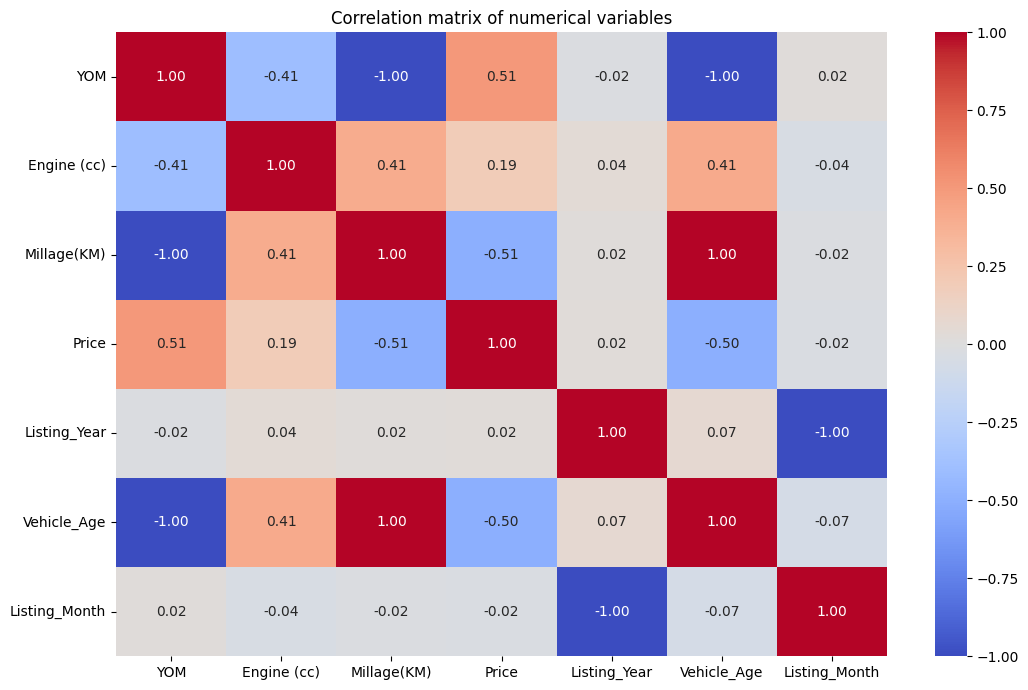

In [ ]:
numeric_eda = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 7))
sns.heatmap(numeric_eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix of numerical variables")
plt.tight_layout()
plt.show()

## 8. Feature definition and train-test separation

`Price` is the prediction target and is excluded from the input feature matrix. The exported index field and raw `Date` string are also excluded. The model inputs include the vehicle attributes and the engineered listing-time features.

The data is divided into training and test partitions using an 80:20 random split with a fixed random state. All models are evaluated using the same held-out test observations, supporting a fair comparison within this experiment.

Preprocessing is fitted within each model pipeline using training data only. This prevents information from the held-out test set from influencing imputation, scaling or category encoding. A random split provides a cross-sectional benchmark; a time-based validation design would be useful for assessing performance on future listings.

In [ ]:
feature_columns = [
    "Brand", "Model", "YOM", "Engine (cc)", "Gear", "Fuel Type",
    "Millage(KM)", "Town", "Leasing", "Condition",
    "AIR CONDITION", "POWER STEERING", "POWER MIRROR",
    "POWER WINDOW", "Listing_Year", "Vehicle_Age", "Listing_Month"
]

X = df[feature_columns].copy()
y = df[TARGET].astype(float).copy()

# Treat object/category columns as categorical; remaining columns numeric.
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print("Train target mean:", round(y_train.mean(), 3))
print("Test target mean:", round(y_test.mean(), 3))

Training rows: 7830
Testing rows: 1958
Categorical features: ['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']
Numerical features: ['YOM', 'Engine (cc)', 'Millage(KM)', 'Listing_Year', 'Vehicle_Age', 'Listing_Month']
Train target mean: 53.417
Test target mean: 53.652


## 9. Leakage-aware preprocessing

Numerical and categorical inputs are processed separately. Numerical variables are imputed and scaled, while categorical variables are imputed and one-hot encoded. Rare categories are grouped using `min_frequency=10`, which reduces the dimensionality associated with high-cardinality variables such as `Brand`, `Model` and `Town`. Categories not encountered during fitting are handled by the encoder's unknown-category setting.

The transformations are contained within the estimator pipeline, so imputation statistics, scaling parameters and category levels are learned from the training partition. Tree-based estimators generally do not require feature scaling, but retaining the common preprocessing pipeline provides a consistent input representation across the compared estimators.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline defined.")

Preprocessing pipeline defined.


## 10. Ensemble learning approaches

The experiment covers several complementary tree-based learning approaches:

- **Decision Tree:** a single tree partitions the feature space into regions and predicts from the observations in each terminal leaf. It provides a reference model but may be sensitive to changes in the training sample.
- **Random Forest (bagging):** trains multiple trees on bootstrap samples and aggregates their predictions. Random feature selection helps reduce correlation among trees and can lower variance.
- **Extra Trees (bagging):** introduces additional randomness into split selection and aggregates many trees. This can reduce variance, although the added randomness may affect bias.
- **Gradient Boosting:** builds trees sequentially, with each stage attempting to correct errors made by the current ensemble.
- **XGBoost:** implements regularised gradient boosting with controls for tree complexity, learning rate and sampling.
- **CatBoost:** is a gradient-boosting implementation designed to work effectively with categorical data. In this notebook, categorical variables are processed by the shared one-hot encoding pipeline before reaching the estimator.
- **Stacking Regressor:** combines base-estimator predictions using a separate Ridge meta-learner trained on out-of-fold predictions.
- **Hybrid Voting Regressor:** averages predictions from Random Forest, Gradient Boosting and XGBoost.

**Bagging** aggregates independently trained learners and is commonly used to reduce variance. **Boosting** builds learners sequentially to improve the current ensemble. **Voting** combines model predictions by averaging, whereas **stacking** learns a second-level model to combine base predictions. Their relative effectiveness is empirical and depends on the dataset and model configuration.

In [ ]:
def make_pipeline(estimator):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

models = {
    "Dummy baseline": make_pipeline(DummyRegressor(strategy="median")),
    "Decision Tree": make_pipeline(DecisionTreeRegressor(
        max_depth=18, min_samples_leaf=5, random_state=RANDOM_STATE
    )),
    "Random Forest (Bagging)": make_pipeline(RandomForestRegressor(
        n_estimators=220, min_samples_leaf=2, max_features=0.9,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    "Extra Trees (Bagging)": make_pipeline(ExtraTreesRegressor(
        n_estimators=220, min_samples_leaf=2, max_features=0.9,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    "Gradient Boosting": make_pipeline(GradientBoostingRegressor(
        n_estimators=160, learning_rate=0.05, max_depth=3,
        loss="huber", random_state=RANDOM_STATE
    )),
    "XGBoost": make_pipeline(XGBRegressor(
        n_estimators=350, max_depth=7, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2.0, objective="reg:squarederror",
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    "CatBoost": make_pipeline(CatBoostRegressor(
        iterations=350, depth=7, learning_rate=0.04,
        loss_function="RMSE", verbose=False,
        random_seed=RANDOM_STATE, allow_writing_files=False
    ))
}

print("Models configured:", list(models.keys()))

Models configured: ['Dummy baseline', 'Decision Tree', 'Random Forest (Bagging)', 'Extra Trees (Bagging)', 'Gradient Boosting', 'XGBoost', 'CatBoost']


## 11. Model fitting and evaluation

Each estimator is fitted using the training partition and evaluated on the same held-out test partition. The Dummy Regressor provides a simple reference point against which the learned models can be compared.

The evaluation metrics are:
- **MAE:** the mean absolute difference between actual and predicted prices. It is expressed in the target units, and lower values indicate smaller average absolute errors.
- **RMSE:** the square root of the mean squared error. It is also expressed in target units and penalises larger errors more strongly than MAE.
- **R²:** the coefficient of determination, which compares model predictions with a mean-prediction reference. Higher values indicate a better fit on the evaluated observations; a negative value indicates performance worse than that reference.

The metrics describe performance on this particular test split and should not be treated as a guarantee of performance on future listings.

In [ ]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

fitted_models = {}
predictions = {}
records = []

for name, pipeline in models.items():
    print(f"Training {name} ...")
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    predictions[name] = pred
    row = {"Model": name, **regression_metrics(y_test, pred)}
    records.append(row)
    print(f"  MAE={row['MAE']:.4f} | RMSE={row['RMSE']:.4f} | R²={row['R2']:.4f}")

results = pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(results.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.4f}"}))

Training Dummy baseline ...
  MAE=28.2047 | RMSE=43.7291 | R²=-0.0655
Training Decision Tree ...
  MAE=6.6449 | RMSE=16.1148 | R²=0.8553
Training Random Forest (Bagging) ...
  MAE=5.4081 | RMSE=13.6657 | R²=0.8959
Training Extra Trees (Bagging) ...
  MAE=5.3031 | RMSE=14.3124 | R²=0.8859
Training Gradient Boosting ...
  MAE=8.5252 | RMSE=18.8067 | R²=0.8029
Training XGBoost ...
  MAE=5.9785 | RMSE=13.8999 | R²=0.8923
Training CatBoost ...
  MAE=7.2337 | RMSE=14.9874 | R²=0.8748


,Model,MAE,RMSE,R2
0,Random Forest (Bagging),5.408,13.666,0.8959
1,XGBoost,5.979,13.900,0.8923
2,Extra Trees (Bagging),5.303,14.312,0.8859
3,CatBoost,7.234,14.987,0.8748
4,Decision Tree,6.645,16.115,0.8553
5,Gradient Boosting,8.525,18.807,0.8029
6,Dummy baseline,28.205,43.729,-0.0655


## 12. Stacking Regressor

Stacking combines predictions from multiple base estimators using a final estimator, referred to as the meta-learner. The base learners in this experiment generate out-of-fold predictions through internal three-fold cross-validation (`cv=3`); these predictions are used to train the Ridge meta-learner.

Unlike simple averaging, stacking learns how to combine the base-model outputs. The additional training stage increases computational cost and does not guarantee an improvement over the strongest individual base learner.

In [ ]:
stack_estimators = [
    ("rf", RandomForestRegressor(
        n_estimators=140, min_samples_leaf=2, max_features=0.9,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    ("extra", ExtraTreesRegressor(
        n_estimators=140, min_samples_leaf=2, max_features=0.9,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    ("gbr", GradientBoostingRegressor(
        n_estimators=120, learning_rate=0.05, max_depth=3,
        loss="huber", random_state=RANDOM_STATE
    ))
]

stack_model = make_pipeline(StackingRegressor(
    estimators=stack_estimators,
    final_estimator=Ridge(alpha=10.0),
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    passthrough=False
))

print("Training Stacking Regressor (may take a few minutes)...")
stack_model.fit(X_train, y_train)
stack_pred = stack_model.predict(X_test)
fitted_models["Stacking Regressor"] = stack_model
predictions["Stacking Regressor"] = stack_pred

stack_row = {"Model": "Stacking Regressor", **regression_metrics(y_test, stack_pred)}
results = pd.concat([results, pd.DataFrame([stack_row])], ignore_index=True)
results = results.sort_values("RMSE").reset_index(drop=True)
display(results.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.4f}"}))

Training Stacking Regressor (may take a few minutes)...


,Model,MAE,RMSE,R2
0,Stacking Regressor,5.338,13.641,0.8963
1,Random Forest (Bagging),5.408,13.666,0.8959
2,XGBoost,5.979,13.900,0.8923
3,Extra Trees (Bagging),5.303,14.312,0.8859
4,CatBoost,7.234,14.987,0.8748
5,Decision Tree,6.645,16.115,0.8553
6,Gradient Boosting,8.525,18.807,0.8029
7,Dummy baseline,28.205,43.729,-0.0655


## 13. Hybrid heterogeneous Voting Regressor

The hybrid voting model averages predictions from Random Forest, Gradient Boosting and XGBoost. For regression, this is prediction averaging rather than class voting. It differs from stacking because it does not fit a separate meta-learner to determine the combination weights.

Averaging can be useful when component models make complementary errors. If their errors are strongly correlated, or if one component is substantially weaker, the combined prediction may not improve. Its effectiveness is therefore assessed using the held-out test metrics.

In [ ]:
voting_estimators = [
    ("rf", RandomForestRegressor(
        n_estimators=180, min_samples_leaf=2, max_features=0.9,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
    ("gbr", GradientBoostingRegressor(
        n_estimators=140, learning_rate=0.05, max_depth=3,
        loss="huber", random_state=RANDOM_STATE
    )),
    ("xgb", XGBRegressor(
        n_estimators=280, max_depth=7, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85,
        reg_lambda=2.0, objective="reg:squarederror",
        n_jobs=-1, random_state=RANDOM_STATE
    ))
]

voting_model = make_pipeline(VotingRegressor(
    estimators=voting_estimators,
    n_jobs=-1
))

print("Training hybrid Voting Regressor ...")
voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)
fitted_models["Hybrid Voting (RF + GBR + XGB)"] = voting_model
predictions["Hybrid Voting (RF + GBR + XGB)"] = voting_pred

voting_row = {
    "Model": "Hybrid Voting (RF + GBR + XGB)",
    **regression_metrics(y_test, voting_pred)
}
results = pd.concat([results, pd.DataFrame([voting_row])], ignore_index=True)
results = results.sort_values("RMSE").reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(results.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.4f}"}))

Training hybrid Voting Regressor ...
FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Stacking Regressor,5.338,13.641,0.8963
1,Random Forest (Bagging),5.408,13.666,0.8959
2,XGBoost,5.979,13.900,0.8923
3,Extra Trees (Bagging),5.303,14.312,0.8859
4,Hybrid Voting (RF + GBR + XGB),6.201,14.335,0.8855
5,CatBoost,7.234,14.987,0.8748
6,Decision Tree,6.645,16.115,0.8553
7,Gradient Boosting,8.525,18.807,0.8029
8,Dummy baseline,28.205,43.729,-0.0655


## 14. Comparative visualisation of model performance

The charts compare MAE, RMSE and R² across the fitted models. Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates a better fit relative to the mean-prediction reference. Consider all three metrics when comparing models because they emphasise different aspects of prediction performance.

In [ ]:
fig = px.bar(results.sort_values("RMSE"), x="Model", y="RMSE",
             color="RMSE", title="Model comparison — RMSE (lower is better)",
             text_auto=".2f")
fig.update_layout(xaxis_tickangle=-35)
fig.show()

fig = px.bar(results.sort_values("MAE"), x="Model", y="MAE",
             color="MAE", title="Model comparison — MAE (lower is better)",
             text_auto=".2f")
fig.update_layout(xaxis_tickangle=-35)
fig.show()

fig = px.bar(results.sort_values("R2", ascending=False), x="Model", y="R2",
             title="Model comparison — R² (higher is better)", text_auto=".3f")
fig.update_layout(xaxis_tickangle=-35)
fig.show()

## 15. Best-model diagnostics: predictions and residuals

The model with the lowest held-out test RMSE is selected for the diagnostic plots. The actual-versus-predicted plot compares estimates with observed target values; points close to the diagonal represent more accurate predictions. Residuals are calculated as `actual − predicted`.

The residual histogram and residual-versus-predicted plot provide additional information about error distribution, unusually large errors and possible patterns not captured by aggregate metrics. These diagnostics complement rather than replace the quantitative model comparison.

In [ ]:
best_model_name = results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_pred = predictions[best_model_name]

print("Lowest test RMSE model:", best_model_name)
print("Metrics:", regression_metrics(y_test, best_pred))

diagnostics = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": best_pred,
    "Residual": y_test.to_numpy() - best_pred
})

fig = px.scatter(diagnostics, x="Actual", y="Predicted",
                 title=f"Actual vs predicted — {best_model_name}",
                 opacity=0.55)
low = min(diagnostics["Actual"].min(), diagnostics["Predicted"].min())
high = max(diagnostics["Actual"].max(), diagnostics["Predicted"].max())
fig.add_shape(type="line", x0=low, y0=low, x1=high, y1=high,
              line=dict(dash="dash"))
fig.show()

fig = px.histogram(diagnostics, x="Residual", nbins=50,
                   title="Residual distribution (actual − predicted)")
fig.show()

fig = px.scatter(diagnostics, x="Predicted", y="Residual",
                 title="Residuals versus predicted values", opacity=0.5)
fig.add_hline(y=0, line_dash="dash")
fig.show()

Lowest test RMSE model: Stacking Regressor
Metrics: {'MAE': 5.33819675070682, 'RMSE': np.float64(13.641004655572715), 'R2': 0.8963135458284409}


## 16. Explainability using permutation feature importance

Permutation feature importance evaluates how much a model's test-set score changes when the values of one input feature are randomly shuffled. A larger positive importance indicates that shuffling the feature reduced predictive performance for the selected scoring function.

The calculation uses a subset of the held-out test observations to keep runtime manageable. Importance values describe the model's predictive reliance on the available features; they do not establish causal effects. Correlated or redundant features can share, mask or redistribute importance. Values close to zero or slightly negative may reflect redundancy, noise or sampling variation and should be interpreted cautiously.

In [ ]:
importance_n = min(1200, len(X_test))
X_imp = X_test.sample(importance_n, random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]

print("Calculating permutation importance for:", best_model_name)
perm = permutation_importance(
    best_model, X_imp, y_imp,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_imp.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df)
fig = px.bar(importance_df.head(15).sort_values("Importance_Mean"),
             x="Importance_Mean", y="Feature", orientation="h",
             error_x="Importance_Std",
             title="Top 15 permutation feature importances")
fig.show()

Calculating permutation importance for: Stacking Regressor


,Feature,Importance_Mean,Importance_Std
0,Brand,10.577247,0.161032
2,YOM,7.847702,0.395071
3,Engine (cc),6.719061,0.215989
4,Gear,5.226973,0.334791
6,Millage(KM),4.995225,0.032930
1,Model,2.627702,0.076480
15,Vehicle_Age,2.420646,0.074918
5,Fuel Type,0.519891,0.057913
12,POWER MIRROR,0.259291,0.027440
13,POWER WINDOW,0.145098,0.072336


## 17. Optional SHAP explainability

This section provides an additional SHAP-based explanation for the selected fitted pipeline. The transformed feature matrix and fitted estimator are accessed separately because preprocessing is contained within the pipeline. The calculation samples up to 300 observations to limit runtime.

SHAP compatibility can depend on the estimator type and installed library version. If this optional analysis is not supported in the runtime, permutation feature importance remains the primary explainability method reported in this notebook.

In [ ]:
try:
    import shap
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]

    X_shap = X_test.sample(min(300, len(X_test)), random_state=RANDOM_STATE)
    X_transformed = fitted_preprocessor.transform(X_shap)

    # TreeExplainer works with supported tree estimators. If unsupported,
    # the exception is caught and permutation importance remains available.
    explainer = shap.TreeExplainer(fitted_estimator)
    shap_values = explainer.shap_values(X_transformed)

    feature_names = fitted_preprocessor.get_feature_names_out()
    shap.summary_plot(
        shap_values, X_transformed,
        feature_names=feature_names,
        max_display=15,
        show=True
    )
except Exception as e:
    print("SHAP could not be generated for this model/environment.")
    print("Reason:", repr(e))
    print("Use the permutation-importance analysis in Section 15.")

SHAP could not be generated for this model/environment.
Reason: InvalidModelError("Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._stacking.StackingRegressor'>")
Use the permutation-importance analysis in Section 15.


## 18. Example vehicle price prediction

The prediction function accepts vehicle attributes using the same raw feature names expected by the training pipeline. The fitted one-hot encoder handles categories that were not present during training according to its configured unknown-category behaviour.

The example prediction is approximately **102.82** in the original `Price` units, equivalent to **LKR 10,282,000 (approximately LKR 102.82 lakhs)** under the dataset's LKR-lakhs convention. This is a model-generated estimate of an advertised asking price, not a guaranteed market value, professional appraisal or confirmed transaction price.

In [ ]:
def predict_vehicle_price(
    brand, model, yom, engine_cc, gear, fuel_type,
    mileage_km, town, leasing, condition,
    air_condition, power_steering, power_mirror, power_window,
    listing_year=None, listing_month=1
):
    if listing_year is None:
        listing_year = fallback_year

    vehicle_age = listing_year - yom

    row = pd.DataFrame([{
        "Brand": brand,
        "Model": model,
        "YOM": yom,
        "Engine (cc)": engine_cc,
        "Gear": gear,
        "Fuel Type": fuel_type,
        "Millage(KM)": mileage_km,
        "Town": town,
        "Leasing": leasing,
        "Condition": condition,
        "AIR CONDITION": air_condition,
        "POWER STEERING": power_steering,
        "POWER MIRROR": power_mirror,
        "POWER WINDOW": power_window,
        "Listing_Year": listing_year,
        "Vehicle_Age": vehicle_age,
        "Listing_Month": listing_month
    }])

    value = float(best_model.predict(row)[0])
    return max(0.0, value)

# Example only — edit values to match a plausible vehicle.
example_prediction = predict_vehicle_price(
    brand="TOYOTA",
    model="AQUA",
    yom=2018,
    engine_cc=1500,
    gear="Automatic",
    fuel_type="Petrol",
    mileage_km=65000,
    town="Colombo",
    leasing="No Leasing",
    condition="USED",
    air_condition="Available",
    power_steering="Available",
    power_mirror="Available",
    power_window="Available",
    listing_year=fallback_year,
    listing_month=1
)
print(f"Example predicted price (original dataset units): {example_prediction:,.2f}")

Example predicted price (original dataset units): 102.82


## 19. Exporting the fitted model and evaluation artifacts

The complete fitted pipeline is saved, including preprocessing and the selected estimator. Saving the full pipeline ensures that inference uses the same transformations learned during training; a separate encoder or imputer should not be fitted in the dashboard.

The output directory contains the model, model-comparison metrics, permutation-importance results, held-out test predictions and model metadata. These artifacts should be kept together so that the dashboard uses the same fitted model and feature definitions as the notebook.

In [ ]:
os.makedirs("ensemblex_lk_outputs", exist_ok=True)

MODEL_PATH = "ensemblex_lk_outputs/ensemblex_lk_best_pipeline.joblib"
joblib.dump(best_model, MODEL_PATH)

results.to_csv("ensemblex_lk_outputs/model_comparison.csv", index=False)
importance_df.to_csv("ensemblex_lk_outputs/permutation_importance.csv", index=False)

test_output = diagnostics.copy()
test_output.index = y_test.index
test_output.to_csv("ensemblex_lk_outputs/test_predictions.csv", index=True)

metadata = {
    "project": "EnsembleX LK",
    "target": TARGET,
    "target_units": "Original dataset units; verify source documentation",
    "selected_model": best_model_name,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "feature_columns": feature_columns,
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "metrics": regression_metrics(y_test, best_pred),
    "note": "Predictions estimate listed asking prices, not confirmed transaction prices."
}
with open("ensemblex_lk_outputs/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model and evaluation outputs:")
for f in os.listdir("ensemblex_lk_outputs"):
    print("-", f)

Saved model and evaluation outputs:
- model_comparison.csv
- permutation_importance.csv
- ensemblex_lk_best_pipeline.joblib
- test_predictions.csv
- model_metadata.json


## 20. Streamlit dashboard generation

The following cell generates the Streamlit application source. The dashboard loads the saved model pipeline and associated evaluation artifacts produced by this notebook. It provides an interactive interface for obtaining predictions using the trained model.

For deployment, keep `app.py`, the `ensemblex_lk_outputs` directory and the generated requirements file together. The dashboard is an interface to the exported model; it does not represent a separately trained model. Ensure the deployed files come from the same notebook run.

In [ ]:
app_source = r"""
import os
import joblib
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(page_title="EnsembleX LK", page_icon="🚗", layout="wide")

BASE = os.path.dirname(os.path.abspath(__file__))
OUT = os.path.join(BASE, "ensemblex_lk_outputs")
MODEL_PATH = os.path.join(OUT, "ensemblex_lk_best_pipeline.joblib")
RESULTS_PATH = os.path.join(OUT, "model_comparison.csv")
IMPORTANCE_PATH = os.path.join(OUT, "permutation_importance.csv")
META_PATH = os.path.join(OUT, "model_metadata.json")

st.title("🚗 EnsembleX LK")
st.caption("Ensemble learning for Sri Lankan used-vehicle asking-price estimation")

if not os.path.exists(MODEL_PATH):
    st.error("Model file not found. Run the Colab notebook and include ensemblex_lk_outputs.")
    st.stop()

model = joblib.load(MODEL_PATH)
results = pd.read_csv(RESULTS_PATH) if os.path.exists(RESULTS_PATH) else pd.DataFrame()
importance = pd.read_csv(IMPORTANCE_PATH) if os.path.exists(IMPORTANCE_PATH) else pd.DataFrame()

page = st.sidebar.radio("Navigate", [
    "Overview", "Model Comparison", "Feature Insights", "Price Predictor"
])

if page == "Overview":
    st.subheader("Project overview")
    st.write("A supervised regression experiment comparing bagging, boosting, stacking and a heterogeneous voting ensemble.")
    if not results.empty:
        best = results.sort_values("RMSE").iloc[0]
        c1, c2, c3 = st.columns(3)
        c1.metric("Lowest-RMSE model", best["Model"])
        c2.metric("Test RMSE", f'{best["RMSE"]:.3f}')
        c3.metric("Test MAE", f'{best["MAE"]:.3f}')
        st.plotly_chart(px.bar(results.sort_values("RMSE"), x="Model", y="RMSE",
                               title="Held-out test RMSE (lower is better)"),
                        use_container_width=True)
    st.info("Output is in the original dataset price units. Verify the source's unit convention before interpreting as currency.")
    st.warning("This model estimates advertised listing prices, not verified transaction values.")

elif page == "Model Comparison":
    st.subheader("Model performance")
    if results.empty:
        st.warning("No model_comparison.csv found.")
    else:
        metric = st.selectbox("Metric", ["RMSE", "MAE", "R2"])
        ascending = metric != "R2"
        st.dataframe(results.sort_values(metric, ascending=ascending), use_container_width=True)
        st.plotly_chart(px.bar(results.sort_values(metric, ascending=ascending),
                               x="Model", y=metric, title=f"{metric} comparison"),
                        use_container_width=True)

elif page == "Feature Insights":
    st.subheader("Permutation feature importance")
    if not importance.empty:
        top = importance.sort_values("Importance_Mean").tail(15)
        st.plotly_chart(px.bar(top, x="Importance_Mean", y="Feature",
                               orientation="h", error_x="Importance_Std",
                               title="Top 15 features"), use_container_width=True)
        st.caption("Permutation importance is model-agnostic. Correlated features can share or mask importance.")
    else:
        st.warning("Feature importance output not found.")

elif page == "Price Predictor":
    st.subheader("Estimate an advertised vehicle price")
    st.caption("The prediction is in the original dataset's price units.")
    with st.form("prediction_form"):
        c1, c2, c3 = st.columns(3)
        brand = c1.text_input("Brand", "TOYOTA")
        model_name = c2.text_input("Model", "AQUA")
        town = c3.text_input("Town", "Colombo")
        yom = c1.number_input("Year of manufacture", min_value=1950, max_value=2026, value=2018)
        engine = c2.number_input("Engine capacity (cc)", min_value=0, value=1500)
        mileage = c3.number_input("Mileage (km)", min_value=0, value=65000)
        gear = c1.selectbox("Transmission", ["Automatic", "Manual"])
        fuel = c2.selectbox("Fuel type", ["Petrol", "Diesel", "Hybrid", "Electric"])
        leasing = c3.selectbox("Leasing", ["No Leasing", "Leasing"])
        condition = c1.selectbox("Condition", ["USED", "BRAND NEW", "RECONDITION"])
        ac = c2.selectbox("Air condition", ["Available", "Not Available"])
        steering = c3.selectbox("Power steering", ["Available", "Not Available"])
        mirror = c1.selectbox("Power mirror", ["Available", "Not Available"])
        window = c2.selectbox("Power window", ["Available", "Not Available"])
        listing_year = c3.number_input("Listing year", min_value=2000, max_value=2035, value=2025)
        month = c1.selectbox("Listing month", list(range(1, 13)), index=0)
        submitted = st.form_submit_button("Estimate price")

    if submitted:
        row = pd.DataFrame([{
            "Brand": brand, "Model": model_name, "YOM": yom,
            "Engine (cc)": engine, "Gear": gear, "Fuel Type": fuel,
            "Millage(KM)": mileage, "Town": town, "Leasing": leasing,
            "Condition": condition, "AIR CONDITION": ac,
            "POWER STEERING": steering, "POWER MIRROR": mirror,
            "POWER WINDOW": window, "Listing_Year": listing_year,
            "Vehicle_Age": listing_year - yom, "Listing_Month": month
        }])
        prediction = float(model.predict(row)[0])
        st.success(f"Estimated asking price: {prediction:,.2f} (original dataset units)")
        st.caption("This is a model estimate, not a professional valuation or guaranteed sale price.")
"""
with open("ensemblex_lk_outputs/app.py", "w", encoding="utf-8") as f:
    f.write(app_source)

requirements = """streamlit
pandas
numpy
scikit-learn
plotly
joblib
xgboost
catboost
"""
with open("ensemblex_lk_outputs/requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

print("Created ensemblex_lk_outputs/app.py and requirements.txt")

Created ensemblex_lk_outputs/app.py and requirements.txt


## 21. Packaging project outputs

After the preceding sections have completed, the packaging cell creates a ZIP archive containing the model and supporting outputs generated by the notebook. The archive is intended to simplify transfer of the trained pipeline, evaluation tables, predictions and dashboard files.

In [ ]:
import shutil
shutil.make_archive("EnsembleX_LK_Submission_Artifacts", "zip", "ensemblex_lk_outputs")

from google.colab import files
files.download("EnsembleX_LK_Submission_Artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 22. Results, discussion and conclusion

### Comparative model performance

The held-out test results produced by the executed notebook are summarised below.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Dummy Baseline | 28.2047 | 43.7291 | -0.0655 |
| Decision Tree | 6.6449 | 16.1148 | 0.8553 |
| Random Forest | 5.4081 | 13.6657 | 0.8959 |
| Extra Trees | 5.3031 | 14.3124 | 0.8859 |
| Gradient Boosting | 8.5252 | 18.8067 | 0.8029 |
| XGBoost | 5.9785 | 13.8999 | 0.8923 |
| CatBoost | 7.2337 | 14.9874 | 0.8748 |
| Stacking Regressor | 5.3382 | 13.6410 | 0.8963 |
| Hybrid Voting | 6.2007 | 14.3352 | 0.8855 |

Stacking Regressor records the lowest RMSE (13.6410) and highest R² (0.8963) in this comparison. Extra Trees records the lowest MAE (5.3031). Thus, the best-performing model depends on the evaluation metric. The difference between Stacking and Random Forest is small: their RMSE values are 13.6410 and 13.6657, respectively, and their R² values are 0.8963 and 0.8959. This is a modest difference on one test split rather than evidence of universal superiority.

The tree-based models substantially outperform the Dummy Baseline on this test set. However, the ensemble approaches do not all perform equally well. Gradient Boosting and CatBoost have higher errors than Random Forest and Stacking in these results, while the Hybrid Voting model does not exceed the strongest individual models across the reported metrics. Extra Trees achieves the lowest MAE but has a higher RMSE than Stacking and Random Forest, reflecting the different error emphasis of MAE and RMSE.

### Permutation feature importance

For the Stacking Regressor, the leading permutation importance values are Brand (10.577247), YOM (7.847702), Engine (cc) (6.719061), Gear (5.226973), Millage(KM) (4.995225), Model (2.627702) and Vehicle_Age (2.420646). Brand and Model describe vehicle identity and market segment; year of manufacture and vehicle age represent age-related differences; engine capacity and transmission distinguish vehicle configurations; and mileage can provide information about vehicle use.

The remaining features have comparatively small importance values in this calculation. Some values are close to zero or slightly negative. Such results should be interpreted cautiously because correlated features can substitute for one another and permutation estimates can vary with the sampled observations. Importance indicates predictive reliance in this model and dataset, not a causal relationship.

### Example prediction

The example vehicle prediction is approximately 102.82 lakhs.

**Estimated asking price: LKR 10,282,000 (approximately LKR 102.82 lakhs).**

This value is an estimate produced by the trained model from the example inputs. It is not a guaranteed market value or a confirmed transaction price.

### Limitations

1. **Geographical and temporal coverage:** the dataset represents Sri Lankan listings within the locations and time period captured by the source. It may not represent all regions, vehicle segments or current market conditions.
2. **Asking-price bias:** advertised prices may differ from negotiated transaction prices. The target therefore reflects listing behaviour rather than confirmed sale amounts.
3. **High-cardinality categorical features:** Brand and Model contain many distinct values. Grouping infrequent categories reduces dimensionality but may limit the model's ability to distinguish rare variants.
4. **Related predictors:** Vehicle_Age is derived from Listing_Year and YOM, while mileage may also be associated with age. Such relationships can affect interpretation and distribute feature importance across related variables.
5. **Single train-test split:** the reported metrics are based on one random held-out sample. Different partitions may produce different estimates of generalisation performance.
6. **Association is not causation:** predictive importance and correlation do not establish that a feature causes a change in asking price.
7. **Unseen vehicles and distribution shift:** predictions for rare brands or models, unusual specifications, or market conditions outside the training data may be unreliable.

### Future improvements

Further work could evaluate model stability using repeated or nested cross-validation, conduct systematic hyperparameter optimisation, and use temporal validation to test performance on later listings. Additional data, especially verified transaction prices and richer vehicle-condition information, could improve target quality and coverage. Explainability could be extended through SHAP, partial dependence or accumulated local effects, alongside subgroup error analysis.

### Conclusion

This experiment demonstrates an end-to-end ensemble regression workflow for estimating Sri Lankan used-vehicle asking prices from listing attributes. On the evaluated held-out split, Stacking provides the lowest RMSE and highest R², while Extra Trees provides the lowest MAE. The results show that several tree-based approaches can provide useful predictive performance, but the small difference between the strongest models and the limitations of the dataset warrant cautious interpretation. The model should be used as an exploratory estimation tool within the dataset's scope, not as a definitive vehicle valuation system.